# Example 2: two belts of icy grains, observed

A warm inner belt (5–15 au) and a cold, eccentric outer belt (Gaussian, peak at 140 au, e = 0.12)
around an A star at 7.7 pc. The grains are a mixture of astronomical silicate and crystalline water
ice; where they are warmer than 110 K the ice sublimates and porous silicate remains. Grains are
removed by radiation pressure if they are unbound when released at pericentre.

The notebook computes the SED, a polarised-light image (Q_φ) at 1.6 µm with a PSF and a
coronagraph mask, thermal images at 24 and 870 µm with a PSF, the grain temperatures and the
vertical optical depth. About two minutes on two cores.

In [1]:
# Setup: this notebook lives in the examples/ folder of the repository
import os, sys
REPO = os.environ.get("DMS_REPO") or os.path.abspath("..")
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__, "from", os.path.relpath(os.path.dirname(dms.__file__), REPO))

DMS 2.0.0 from python/dms


## The system

Lists give one value per belt (`disk`) or per dust component (`dust`).
`load_optics`/`save_optics` keep the Mie results in `cache/`, so running a cell again is fast.

In [2]:
system = dms.Model(
    star={"teff": 8590.0, "radius": 1.84, "mass": 1.92, "distance": 7.7},   # A star at 7.7 pc
    disk={
        "n_belts": 2,
        "density_law": ["powerlaw", "gaussian"],
        "alpha": [1.0, 0.0],                             # inner belt: n ~ a^-1
        "mu": [0.0, 140.0], "sigma": [0.0, 8.0],         # outer belt: Gaussian, peak at 140 au
        "r_in": [5.0, 110.0], "r_out": [15.0, 170.0],    # semi-major axes [au]
        "eccentricity": [0.0, 0.12], "omega": [0.0, 40.0],
        "belt_mass_fraction": [0.02, 0.98],
        "vertical": "gaussian", "h_over_r": 0.03,
        "dust_mass": 1e-8,                               # M_sun
        "inclination": 66.0, "position_angle": 156.0,
    },
    dust={
        "n_components": 2,
        "optical_data": ["kim2019/ice_astrosilicate_MG/Sil50cice50",     # 50 % silicate, 50 % ice
                         "kim2019/porous_astrosilicate/as50vac50"],      # porous silicate (residue)
        "bulk_density": [2.25, 1.75],                    # g/cm^3, by volume (silicate 3.5, ice 1.0)
        "abundance": [100.0, 0.0],                       # the residue only forms by sublimation
        "sublimation": True,
        "t_sublimation": [110.0, -1.0],                  # K; the residue does not sublimate
        "sublimation_residue": [2, 0],                   # component 1 becomes component 2
        "a_min": 1.0, "a_max": 1000.0, "q": 3.5,
        "blowout_release": "pericentre",                 # grains released at pericentre
    },
    run={"load_optics": True, "save_optics": True},
)

## Three runs

The SED (direct integration), Q_φ at 1.6 µm (0.2″ PSF, coronagraph mask of 2.5″ = 19 au radius,
which hides the inner belt), and thermal emission at 24 and 870 µm (PSF of 0.8″ and 0.4″).

In [3]:
sed = system.copy().update(
    run={"mode": "sed", "optics_cache_name": "example2_sed"},
    wavelengths={"lambda_min": 1.0, "lambda_max": 2000.0, "n_lambda": 80}).run()

pol = system.copy().update(
    run={"mode": "image", "emission": "polarisation", "optics_cache_name": "example2_pol"},
    wavelengths={"lambda": [1.6]},
    image={"n_pixels": 201, "psf": "gaussian", "psf_fwhm": 0.2, "mask_radius": 2.5}).run()

th = system.copy().update(
    run={"mode": "image", "emission": "thermal", "optics_cache_name": "example2_th"},
    wavelengths={"lambda": [24.0, 870.0]},
    image={"n_pixels": 201, "psf": "gaussian", "psf_fwhm": [0.8, 0.4]}).run()

## Summary

In [4]:
def flux_at(lam):                          # log-log interpolation of the SED
    return np.exp(np.interp(np.log(lam), np.log(sed.wavelength), np.log(sed.sed["thermal"])))

a_kept = sed.grains["a"][sed.grains["number"][:, 0] > 0].min()   # smallest icy grain after blow-out
print(f"stellar luminosity       {sed.luminosity_lsun:.1f} L_sun")
print(f"fractional luminosity    f_d = {sed.f_d:.2e}")
print(f"largest radial tau       {sed.tau_radial:.1e}   (optically thin if << 0.1)")
print(f"blow-out threshold       beta >= {sed.blowout_beta[0]:.2f} ... {sed.blowout_beta[1]:.2f}; "
      f"smallest icy grain left: {a_kept:.1f} micron")
print(f"disk flux density        {flux_at(24.0):.3f} Jy at 24 micron, {1e3 * flux_at(870.0):.2f} mJy at 870 micron")
qphi = pol.image("Qphi", observed=True)[0]
print(f"polarised flux (Q_phi)   {1e3 * np.nansum(qphi):.2f} mJy at 1.6 micron, outside the mask")

stellar luminosity       16.6 L_sun
fractional luminosity    f_d = 1.00e-04
largest radial tau       2.8e-03   (optically thin if << 0.1)
blow-out threshold       beta >= 0.44 ... 0.50; smallest icy grain left: 5.1 micron
disk flux density        4.403 Jy at 24 micron, 18.38 mJy at 870 micron
polarised flux (Q_phi)   0.45 mJy at 1.6 micron, outside the mask


## Figure

Top: SED; temperatures of the icy grains for four sizes (the smallest left after blow-out, 20, 100
and 1000 µm) with the sublimation temperature; Q_φ at 1.6 µm. Bottom: thermal emission at 24 µm
(logarithmic scale) and 870 µm; vertical optical depth towards pericentre and apocentre of the
outer belt and its azimuthal mean.

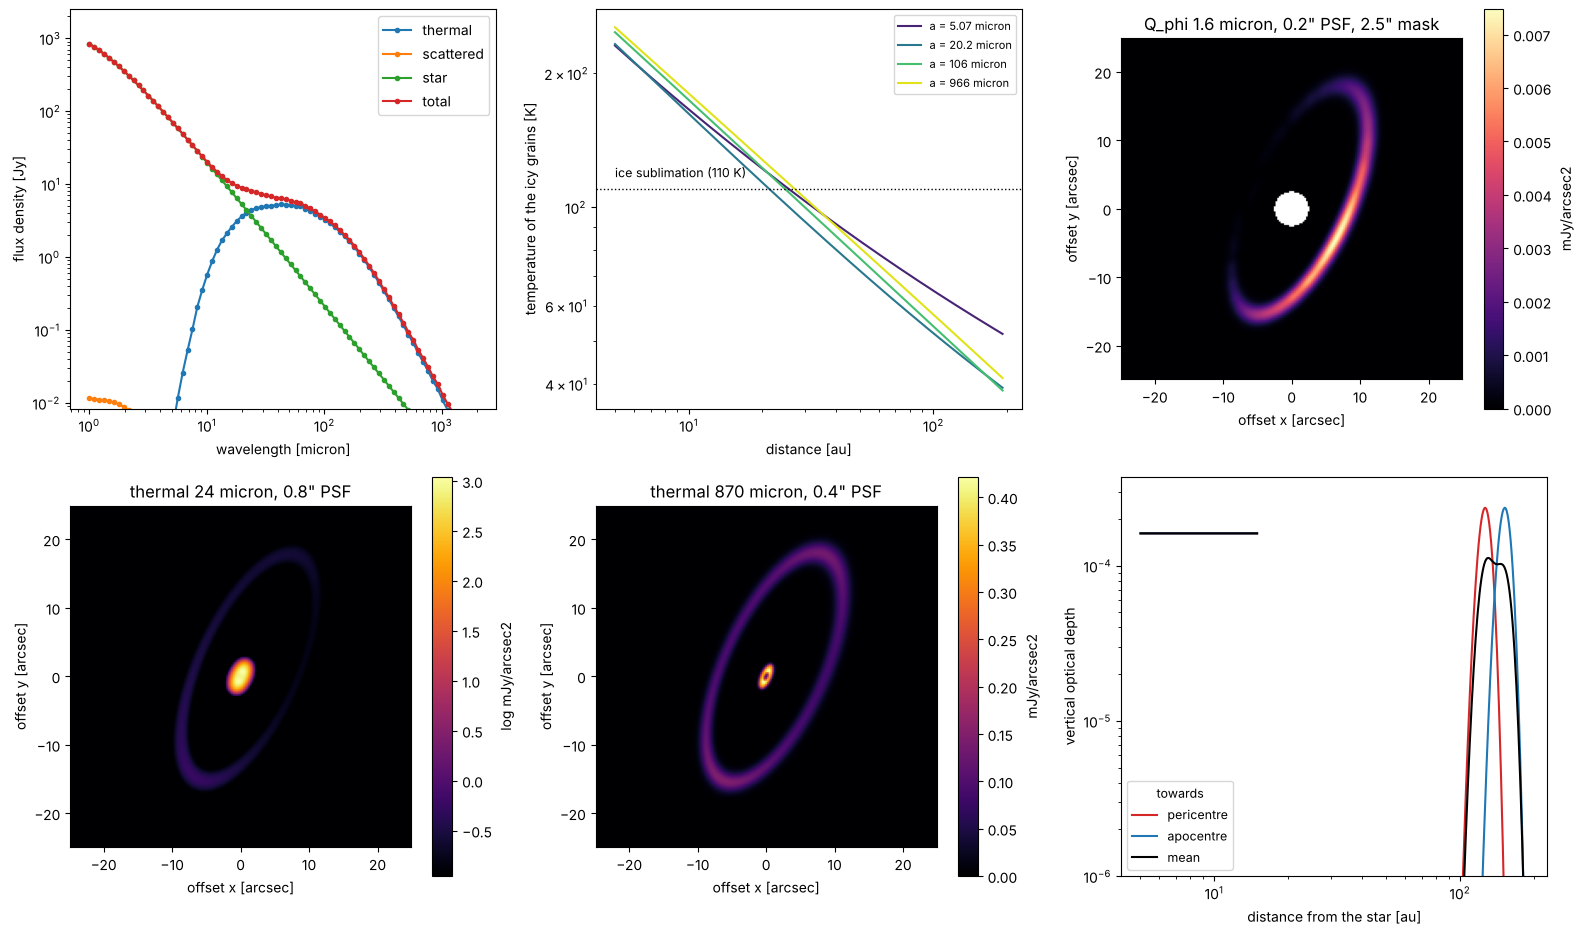

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9.5))

dms.plot.sed(sed, ax=ax[0, 0])
top = sed.sed["total"].max()
ax[0, 0].set_ylim(1e-5 * top, 3 * top)

T, a = sed.temperature, sed.grains["a"]                  # T["T"][distance, component, size]
for i, c in zip(np.searchsorted(a, [a_kept, 20.0, 100.0, 1000.0]), plt.cm.viridis([0.1, 0.4, 0.7, 0.95])):
    i = min(i, len(a) - 1)
    ax[0, 1].loglog(T["r_au"], T["T"][:, 0, i], color=c, label=f"a = {a[i]:.3g} micron")
ax[0, 1].axhline(110.0, color="k", ls=":", lw=1)
ax[0, 1].text(T["r_au"][0], 115.0, "ice sublimation (110 K)", fontsize=9, va="bottom")
ax[0, 1].set_xlabel("distance [au]")
ax[0, 1].set_ylabel("temperature of the icy grains [K]")
ax[0, 1].legend(fontsize=8)

dms.plot.image(pol, "Qphi", observed=True, unit="mJy/arcsec2", log=False, ax=ax[0, 2], cmap="magma", vmin=0)
ax[0, 2].set_title('Q_phi 1.6 micron, 0.2" PSF, 2.5" mask')
dms.plot.image(th, "thermal", il=0, observed=True, unit="mJy/arcsec2", ax=ax[1, 0])
ax[1, 0].set_title('thermal 24 micron, 0.8" PSF')
dms.plot.image(th, "thermal", il=1, observed=True, unit="mJy/arcsec2", log=False, ax=ax[1, 1])
ax[1, 1].set_title('thermal 870 micron, 0.4" PSF')

tau = sed.tau_profile
for key, c in (("pericentre", "C3"), ("apocentre", "C0"), ("mean", "k")):
    ax[1, 2].loglog(tau["r_au"], np.where(tau[key] > 0, tau[key], np.nan), color=c, label=key)
ax[1, 2].set_xlabel("distance from the star [au]")
ax[1, 2].set_ylabel("vertical optical depth")
ax[1, 2].set_ylim(1e-6, None)
ax[1, 2].legend(fontsize=9, title="towards", title_fontsize=9)

fig.tight_layout()
plt.show()